In [2]:
import torch
import torch.nn as nn
torch.manual_seed(42)
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])



In [4]:

print("X.shape =",X.shape)
print("y.shape =",y.shape)


X.shape = torch.Size([190, 10])
y.shape = torch.Size([190])


In [ ]:
X = X.unsqueeze(-1)#0 il ajoute la dimension au debut; -1 il ajoute la dimension a la fin
y = y.unsqueeze(-1)#0 il ajoute la dimension au debut; -1 il ajoute la dimension a la fin

X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

In [6]:
print("X.shape =",X.shape)
print("y.shape =",y.shape)

X.shape = torch.Size([190, 10, 1])
y.shape = torch.Size([190, 1])


Text(0, 0.5, 'y')

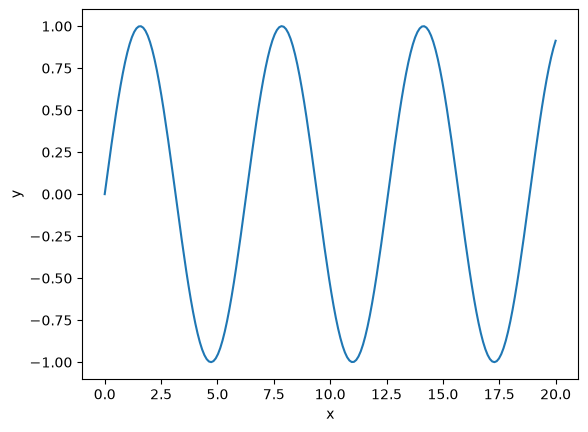

In [7]:
import matplotlib.pyplot as plt
plt.plot(periode, serie)
plt.xlabel("x")
plt.ylabel("y")

In [10]:
X_train[1]

tensor([[0.1003],
        [0.1997],
        [0.2970],
        [0.3913],
        [0.4816],
        [0.5671],
        [0.6469],
        [0.7202],
        [0.7861],
        [0.8442]])

In [9]:
y_train[1]

tensor([0.8937])

In [12]:
class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn=nn.RNN( # créer un reseau RNN avec une cellule RNN
            input_size = 1, #car nous avons une seule valeure
            hidden_size = 16, #une cellule RNN aura 16 unités. c'est grace à ces 16 unités qu'il va calculer l'etat cachée
            batch_first = True
        )
        self.sortie = nn.Linear(16,1)
    def forward(self, x):
        etats, _ = self.rnn(x)
        dernier_etat = etats[:, -1, :]
        return self.sortie(dernier_etat)

modele = SimpleRNN()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

In [13]:
# Boucle d'entrainement
model.train()
for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)
    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()
    if (epoch + 1) % 50 ==0:
        print(f"Epoch {epoch +1:3d} | Erreur : {perte.item():.6f}")
        
model.eval()
with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)
    
print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"\nValeur réelle : {y_test[0].item():.4f}")
print(f"\nValeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001416
Epoch 100 | Erreur : 0.000190
Epoch 150 | Erreur : 0.000063
Epoch 200 | Erreur : 0.000031
Epoch 250 | Erreur : 0.000020
Epoch 300 | Erreur : 0.000016

Erreur de test : 0.000020

Valeur réelle : -0.3639

Valeur prédite : -0.3635


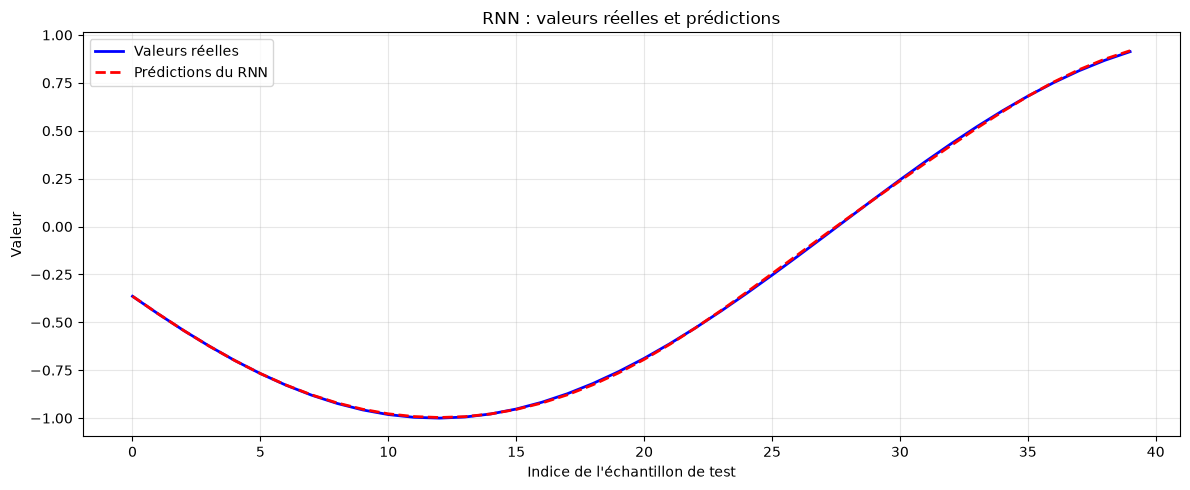

In [14]:
# representer les sequences

import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))
plt.plot(valeurs_reelles, label="Valeurs réelles", color="blue", linewidth=2)
plt.plot(
    valeurs_predites,
    label="Prédictions du RNN",
    color="red",
    linestyle="--",
    linewidth=2,
)
plt.title("RNN : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:

class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=16,
            num_layers=1,
            batch_first=True
        )
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, (h_final, c_final) = self.lstm(x)
        dernier_etat = etats[:, -1, :]
        return self.sortie(dernier_etat)

modele = SimpleLSTM()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

In [16]:
# Boucle d'apprentissage du LSTM
modele.train()
for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)
    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")

modele.eval()
with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.002445
Epoch 100 | Erreur : 0.000142
Epoch 150 | Erreur : 0.000010
Epoch 200 | Erreur : 0.000008
Epoch 250 | Erreur : 0.000006
Epoch 300 | Erreur : 0.000006

Erreur de test : 0.000008
Valeur réelle  : -0.3639
Valeur prédite : -0.3637


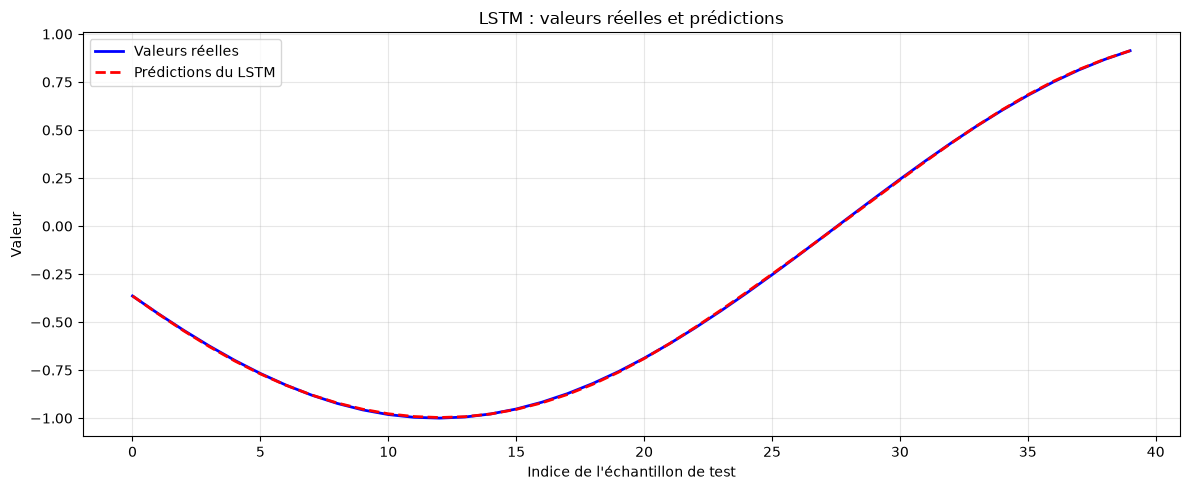

In [17]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))
plt.plot(valeurs_reelles, label="Valeurs réelles", color="blue", linewidth=2)
plt.plot(
    valeurs_predites,
    label="Prédictions du LSTM",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("LSTM : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10):#longueur_max <=> context windows
        super().__init__()
        dimension = 16
        self.projection = nn.Linear(1, dimension) # j'appelle une appli lineaire et elle va me donner un vecteur de dim16
        self.positions = nn.Embedding(longueur_max, dimension)

        couche = nn.TransformerEncoderLayer(
            d_model=dimension,
            nhead=2,
            dim_feedforward=32,
            dropout=0.0,
            batch_first=True
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=1)
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        longueur = x.size(1)
        x = self.projection(x)  # (B, 10, 16)
        indices = torch.arange(longueur, device=x.device)
        positions = self.positions(indices)  # (10, 16)
        x = x + positions.unsqueeze(0)  # (B, 10, 16)
        representations = self.encodeur(x)  # (B, 10, 16)
        derniere_position = representations[:, -1, :]  # (B, 16)
        return self.sortie(derniere_position)  # (B, 1)


modele = MiniTransformer(longueur_max=longueur_sequence)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

In [19]:
# Boucle d'apprentissage du transformer
modele.train()
for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
#  Tester le modèle
# --------------------------------------------------
modele.eval()
with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")


Epoch  50 | Erreur : 0.000836
Epoch 100 | Erreur : 0.000254
Epoch 150 | Erreur : 0.000149
Epoch 200 | Erreur : 0.000066
Epoch 250 | Erreur : 0.000020
Epoch 300 | Erreur : 0.000009

Erreur de test : 0.000011
Valeur réelle  : -0.3639
Valeur prédite : -0.3678


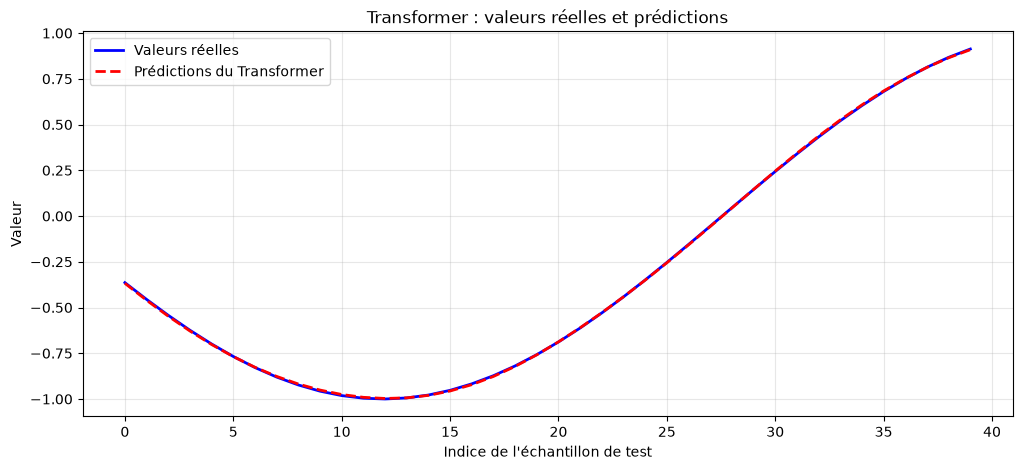

In [20]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du Transformer",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Transformer : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)

In [22]:
#GPT 2
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# --------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# --------------------------------------------------

nom_modele = "gpt2"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForCausalLM.from_pretrained(nom_modele)

# GPT-2 ne possède pas de token de padding dédié.
tokenizer.pad_token = tokenizer.eos_token
modele.config.pad_token_id = tokenizer.pad_token_id

modele.eval()

# --------------------------------------------------
# 2. Transformer le texte en tokens
# --------------------------------------------------

# GPT-2 est principalement entraîné sur de l'anglais.
texte = "Artificial intelligence can help people"

entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Dimensions de l'entrée :", entrees["input_ids"].shape)
# (1, nombre de tokens du texte)

# --------------------------------------------------
# 3. Générer la suite, un token après l'autre
# --------------------------------------------------

with torch.no_grad():
    sortie = modele.generate(
        **entrees,
        max_new_tokens=50,     # Générer au maximum 50 tokens
        do_sample=True,        # Tirage aléatoire des tokens
        temperature=0.8,       # Contrôler la diversité
        top_p=0.9,             # Limiter les candidats probables
        pad_token_id=tokenizer.pad_token_id
    )

# --------------------------------------------------
# 4. Reconvertir les tokens en texte
# --------------------------------------------------

texte_genere = tokenizer.decode(
    sortie[0],
    skip_special_tokens=True
)

print("\nTexte généré :")
print(texte_genere)

c:\Users\alex.chimi\vscode\deepdive_transformer\lab_pytorch_v1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\alex.chimi\vscode\deepdive_transformer\lab_pytorch_v1\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\alex.chimi\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run 

Dimensions de l'entrée : torch.Size([1, 6])

Texte généré :
Artificial intelligence can help people understand their own emotions and emotions can help us be better people.

In the past year, psychologists have also discovered that people who are very good at predicting their own emotions have the highest levels of intelligence in the world. These people have the highest


In [23]:
#BERT
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

# --------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# --------------------------------------------------

nom_modele = "bert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForMaskedLM.from_pretrained(nom_modele)
modele.eval()

# --------------------------------------------------
# 2. Préparer un texte avec un token masqué
# --------------------------------------------------

texte = f"Paris est la {tokenizer.mask_token} de la France."

entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Texte :", texte)
print("Dimensions de l'entrée :", entrees["input_ids"].shape)
# (1, nombre de tokens du texte)

# Repérer la position du masque dans la séquence
position_masque = (
    entrees["input_ids"][0] == tokenizer.mask_token_id
).nonzero(as_tuple=True)[0].item()

# --------------------------------------------------
# 3. Prédire le token masqué
# --------------------------------------------------

with torch.no_grad():
    sortie = modele(**entrees)

# sortie.logits : (1, nombre de tokens, taille du vocabulaire)
scores = sortie.logits[0, position_masque, :]

# Transformer les scores en probabilités
probabilites = torch.softmax(scores, dim=-1)

# Sélectionner les 5 tokens les plus probables
top_probabilites, top_indices = torch.topk(probabilites, k=5)

# --------------------------------------------------
# 4. Afficher les propositions
# --------------------------------------------------

print("\nPropositions de BERT :")

for probabilite, indice in zip(top_probabilites, top_indices):
    token = tokenizer.decode([indice.item()]).strip()
    phrase = texte.replace(tokenizer.mask_token, token)

    print(f"{probabilite.item():.2%} | {phrase}")

c:\Users\alex.chimi\vscode\deepdive_transformer\lab_pytorch_v1\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\alex.chimi\.cache\huggingface\hub\models--bert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 202/202 [00:00<00:00, 2119.61it/s

Texte : Paris est la [MASK] de la France.
Dimensions de l'entrée : torch.Size([1, 10])

Propositions de BERT :
36.32% | Paris est la capitale de la France.
21.09% | Paris est la ville de la France.
3.16% | Paris est la Cité de la France.
1.67% | Paris est la préfecture de la France.
1.64% | Paris est la banlieue de la France.
